In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, ConcatDataset
from torchvision.utils import draw_bounding_boxes
from torchvision import transforms
import matplotlib.pyplot as plt
from math import ceil, floor
from datetime import datetime 
from scipy.special import expit
torch.manual_seed(123)

# Model definition

In [2]:
device = (torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
print(f"Training on device {device}.")

class LocalizationNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
 
        self.fc1_input_features = 32 * 12 * 15
        self.fc1 = nn.Linear(self.fc1_input_features, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 15)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = x.view(-1, self.fc1_input_features)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        detection = x[:, 0:1]                # leave as is, BCEWithLogitsLoss applies sigmoid
        boxes = torch.sigmoid(x[:, 1:5])     # constrain to [0, 1]
        classes = x[:, 5:]                   # raw data, CrossEntropyLoss does softmax 

        return torch.cat([detection, boxes, classes], dim=1)


Training on device cuda.


## Localization


In [3]:
def localization_loss(y_pred, y_true):
    detection_c = nn.BCEWithLogitsLoss()
    localization_c = nn.MSELoss(reduction='none')
    classification_c = nn.CrossEntropyLoss(reduction='none')
    obj_mask = y_true[:,0]

    det_loss = detection_c(y_pred[:,0], y_true[:,0])
    loc_loss = (localization_c(y_pred[:,1:5], y_true[:,1:5]).mean(dim=1) * obj_mask).mean()
    cls_loss = (classification_c(y_pred[:,5:], y_true[:,-1].long())*obj_mask).mean()

    return det_loss + loc_loss + cls_loss

### Load data and preprocessing

In [4]:
localization_test = torch.load("data/localization_test.pt")
localization_train = torch.load("data/localization_train.pt")
localization_val = torch.load("data/localization_val.pt")


C:\Users\eirik\AppData\Local\Temp\ipykernel_48456\593454538.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  localization_test = torch.load("data/localization_test.pt")
C

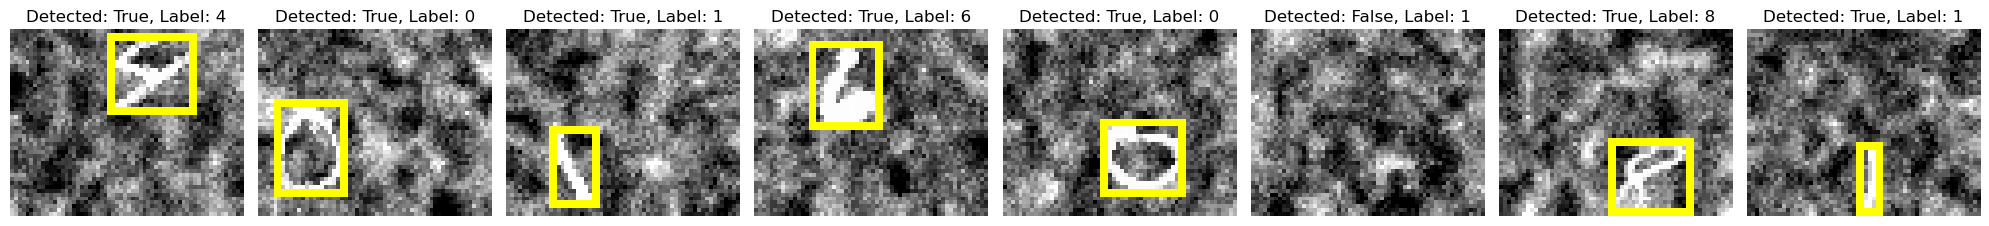

In [5]:
def visualize_samples(dataset, num_samples=8):
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 3))
    
    for i in range(num_samples):
        img, label = dataset[i]
        
        # Convert to uint8 RGB (required by draw_bounding_boxes)
        img = img.squeeze(0)                  
        img = img.repeat(3, 1, 1)                  
        img = (img * 255).byte()                   

        if label[0] == 1:
            x, y, w, h = label[1:5]
            x1 = (x*60) - ((w*60)/2)
            y1 = (y*48) - ((h*48)/2)
            x2 = (x*60) + ((w*60)/2)
            y2 = (y*48) + ((h*48)/2)
            boxes = torch.tensor([[x1, y1, x2, y2]]).float()   
            img = draw_bounding_boxes(img, boxes, colors=(255, 255, 0), width=2)
        
        
        # (3, H, W) -> (H, W, 3) for matplotlib
        axes[i].imshow(img.permute(1, 2, 0))
        axes[i].set_title(f"Detected: {bool(label[0])}, Label: {label[-1]:.0f}")
        axes[i].axis("off")
    
    plt.tight_layout()
    plt.show()

visualize_samples(localization_train)

### Normalize Images

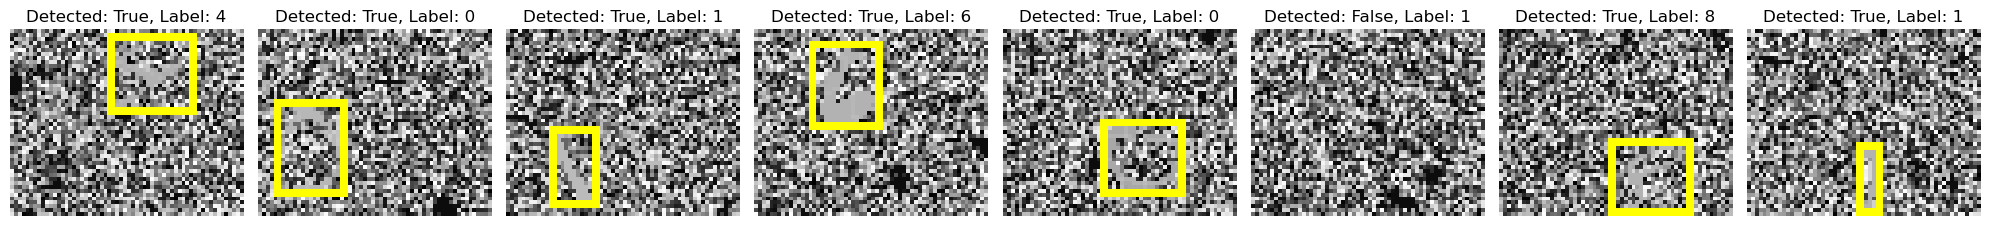

In [6]:
def normalize(dataset):
    #Compute mean/standard deviation
    loader = DataLoader(dataset)
    mean = 0
    std = 0
    total = 0
    for img, _ in loader:
        batch_size = img.size(0)
        img = img.view(batch_size, img.size(1), img.size(2)*img.size(3))  # flatten pixels to 1 dim for mean/std
        mean += img.mean(2).sum(0)
        std += img.std(2).sum(0)
        total += batch_size

    mean /= total
    std /= total
    
    # Perform normalization
    normalize_fn = transforms.Normalize(mean=mean, std=std)
    normalized_tensors = normalize_fn(dataset.tensors[0])  
    labels = dataset.tensors[1]                           

    return TensorDataset(normalized_tensors, labels)

loc_train_normalized = normalize(localization_train)
visualize_samples(loc_train_normalized)


In [7]:
imgs = localization_train.tensors[0]
normalized_imgs = loc_train_normalized.tensors[0]

print(f'Original mean: {imgs.mean():.3f}, std: {imgs.std():.3f}')
print(f'Normalized mean: {normalized_imgs.mean():.3f}, std: {normalized_imgs.std():.3f}')


Original mean: 0.417, std: 0.214
Normalized mean: 0.000, std: 1.007


### Training

In [9]:

net = LocalizationNet()
criterion = localization_loss
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
trainloader = DataLoader(loc_train_normalized, batch_size=32)

for epoch in range(3):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        images, labels = data
        optimizer.zero_grad()

        outputs = net(images)
        loss = criterion(outputs.squeeze(0), labels.squeeze(0))  # remove batch dim
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 2000 == 1999:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
    

print('Finished Training')



Finished Training


### Predictions

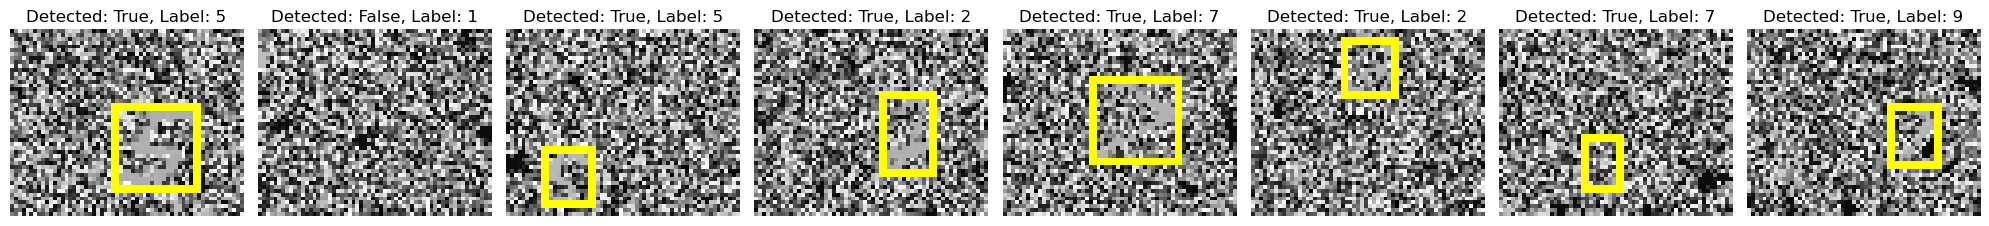

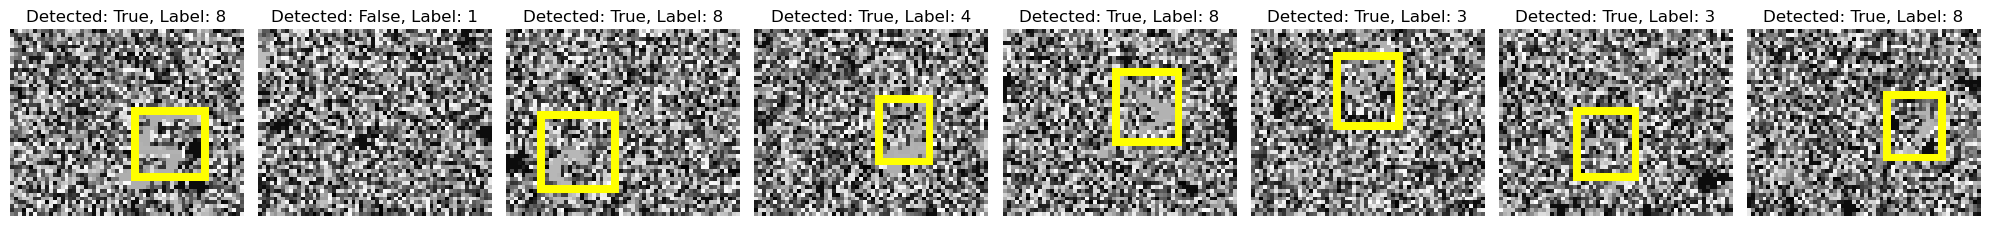

In [23]:

loc_val_normalized = normalize(localization_val)
val_loader = DataLoader(loc_val_normalized)
visualize_samples(loc_val_normalized)

loc_val_images = loc_val_normalized.tensors[0]
predictions = []
for i, data in enumerate(val_loader):
    images, labels = data 
    outputs = net(images)
    predictions += outputs

labels = []
for pred in predictions:
    detected = torch.sigmoid(pred[0])  
    detected_bin = (detected > 0.5).float()
    x, y, w, h = pred[1], pred[2], pred[3], pred[4]  
    class_label = torch.argmax(pred[5:]).float() 
    
    label = torch.stack([detected_bin, x, y, w, h, class_label])
    labels.append(label)

val_images = loc_val_normalized.tensors[0]  
pred_dataset = TensorDataset(val_images, torch.stack(labels))
visualize_samples(pred_dataset)

### Model selection and evaluation

In [24]:
def intersection(bb1, bb2):
    (x1, y1, w1, h1) = bb1
    (x2, y2, w2, h2) = bb2
    s1 = min(y1+h1, y2+h2) - max(y1, y2)
    s2 = min(x1+w1, x2+w2) - max(x1, x2)
    return max(s1, 0) * max(s2, 0)


def IoU(bb1, bb2):
    (x1, y1, w1, h1) = bb1
    (x2, y2, w2, h2) = bb2

    a1 = h1 * w1
    a2 = h2 * w2

    i = intersection(bb1, bb2)

    return i / (a1 + a2 - i + 1e-6)
   
def compute_IoU_localization(model, loader, device):
    model.eval()
    total_IoU = 0
    count = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            for b in range(len(images)):
                if labels[b, 0].item() == 1:
                    pred_detection = torch.sigmoid(outputs[b, 0]).round().item()
                    if pred_detection == 1:
                        bb1 = (labels[b,1].item(), labels[b,2].item(), 
                               labels[b,3].item(), labels[b,4].item())
                        bb2 = (outputs[b,1].item(), outputs[b,2].item(), 
                               outputs[b,3].item(), outputs[b,4].item())
                        total_IoU += IoU(bb1, bb2)
                    count += 1
    
    model.train()
    return total_IoU / count if count > 0 else 0


def compute_accuracy_localization(model, loader, device):
    model.eval()
    total_correct = 0
    n_samples = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            
            pred_detections = torch.sigmoid(outputs[:, 0]).round()
            pred_classes = torch.argmax(outputs[:, 5:], dim=1).float()
            
            correct_detections = (pred_detections == labels[:, 0])
            correct_classes = (pred_classes == labels[:, -1])
            
            total_correct += (correct_detections & correct_classes).sum().item()
            n_samples += len(images)
    
    model.train()
    return total_correct / n_samples
    
    

In [25]:
def train_loop(dataset, eval_loader, device, n_epochs=10, lr=0.001, momentum=0.09, batch_size=16, visualize=False):
    net = LocalizationNet().to(device)
    criterion = localization_loss
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    trainloader = DataLoader(dataset, batch_size=batch_size, shuffle=True) #dataset should be normalized from before

    history = {
        'IoU' : [],
        'Detection accuracy': [],
        'Label accuracy': [],
        'Training loss': [],
        'Validation accuracy': []
    }
    for epoch in range(n_epochs):
        train_pred_imgs = []
        train_pred_labels = []
        correct_detections = 0
        correct_labels = 0
        training_loss = 0
        n_samples = 0
        validation_accuracy = 0

        for i, (images, labels) in enumerate(trainloader, 0):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(images)

            loss = criterion(outputs, labels)
            training_loss += loss.item()
            loss.backward()
            optimizer.step()

            pred_detections = torch.sigmoid(outputs[:, 0]).round().detach()
            pred_classes = torch.argmax(outputs[:, 5:].detach(), dim=1).float()
            
            correct_detections += (pred_detections == labels[:, 0]).sum().item()
            correct_labels += (pred_classes == labels[:, -1]).sum().item()
            n_samples += len(images)

            if visualize:
                for b in range(len(images)):
                    pred_label = torch.cat([pred_detections[b].unsqueeze(0),
                                            outputs[b, 1:5].detach(),
                                            pred_classes[b].unsqueeze(0)]).cpu()
                    train_pred_imgs.append(images.squeeze(0).detach()).cpu()
                    train_pred_labels.append(pred_label)

        if visualize:
            train_pred_dataset = TensorDataset(
                torch.stack(train_pred_imgs),
                torch.stack(train_pred_labels))

            visualize_samples(train_pred_dataset)
            visualize_samples(loc_train_normalized)
        
        validation_accuracy = compute_accuracy_localization(net, eval_loader, device)
        
        history['Detection accuracy'].append(correct_detections / n_samples)
        history['Label accuracy'].append(correct_labels / n_samples)
        history['Training loss'].append(training_loss / len(trainloader))
        if (epoch + 1) % 5 == 0 or epoch == n_epochs - 1:
            history['IoU'].append(compute_IoU_localization(net, eval_loader, device))
        history['Validation accuracy'].append(validation_accuracy)

    return net, history

val_loader = DataLoader(loc_val_normalized, batch_size=16)
net, history = train_loop(loc_train_normalized, val_loader, device, n_epochs=1)

In [26]:
print(history)

{'IoU': [0.13860513426961213], 'Detection accuracy': [0.9068518518518518], 'Label accuracy': [0.14873737373737372], 'Training loss': [2.414569438643575], 'Validation accuracy': [0.12454545454545454]}


In [27]:
import gc

def clear_memory():
    gc.collect()
    torch.cuda.empty_cache()

del net 
clear_memory()

## Model Selection:

In [29]:
import itertools
import random


def select_best_model(hyperparameter_grid, dataset, eval_loader, device, n_models):
    seed = 265
    random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    best_iou = (0, 0)
    best_parameters = None
    best_model = None
    all_histories = {}

    for i in range(n_models):
        parameters = random.choice(hyperparameter_grid)
        lr, bs, momentum, epochs = parameters
        print("Training model using parameters: ", parameters)

        net = LocalizationNet()
        net, history = train_loop(dataset, eval_loader, device, epochs, lr, momentum, bs)
        all_histories[i] = history

        max_iou = max(history['IoU'])
        if max_iou > best_iou[0]:
            best_iou = (max_iou, i)
            best_model = net
            best_parameters = parameters 
    
        del net
        clear_memory()
        

    return best_iou, best_model, best_parameters, all_histories

learning_rates = [0.001, 0.005, 0.01, 0.05]
batch_sizes = [8, 16, 32]
momentums = [1, 0.95, 0.9, 0.8, 0.6]
n_epochs = [10, 15, 20]
grid = list(itertools.product(learning_rates, batch_sizes, momentums, n_epochs))

eval_loader = DataLoader(normalize(localization_val), batch_size = 16)
dataset = loc_train_normalized

best_iou, best_model, best_parameters, all_histories = select_best_model(grid, dataset, eval_loader, device, 10)


Training model using parameters:  (0.01, 8, 0.8, 15)
Training model using parameters:  (0.01, 32, 1, 20)
Training model using parameters:  (0.005, 32, 0.95, 20)
Training model using parameters:  (0.01, 32, 0.95, 10)
Training model using parameters:  (0.01, 32, 0.6, 15)
Training model using parameters:  (0.005, 32, 0.95, 20)
Training model using parameters:  (0.005, 8, 0.9, 15)
Training model using parameters:  (0.005, 8, 0.6, 10)
Training model using parameters:  (0.005, 8, 0.95, 15)


KeyboardInterrupt: 

In [ ]:
for history in all_histories:
    print(all_histories[history])
    print("-----------------------")

print("Best IoU: ", best_iou, "Parameters: ", best_parameters)


{'IoU': [0.12894578336448714, 0.12894578336448714, 0.12894578336448714, 0.12894578336448714], 'Detection accuracy': [0.9089057239057239, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091, 0.9090909090909091], 'Label accuracy': [0.115, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697, 0.1146969696969697], 'Training loss': [2.4303896021335682, 2.4293446562022427, 2.429344655624336

## Training best model further:

IoU is still quite low, and validation data should be added to training before final test.


In [ ]:
lr, bs, momentum, epochs = best_parameters

combined_data = ConcatDataset([loc_train_normalized, loc_val_normalized])
test_loader = DataLoader(normalize(localization_test), batch_size=32)


net, history = train_loop(combined_data, test_loader, device, 20, lr, momentum, bs)


In [ ]:
iou = compute_IoU_localization(net, test_loader, device)
accuracy = compute_accuracy_localization(net, test_loader, device)

print(iou)
print(accuracy)

0.5981667973475984
0.8159090909090909
